<a href="https://colab.research.google.com/github/suryapratapsingh009/python-model/blob/main/updated_Brain_Tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!unzip "/content/quince-strawberry-61-090826.zip" -d "/content/extracted_output/"

Streaming output truncated to the last 5000 lines.
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1476.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1477.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1478.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1485.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image3416.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1487.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1489.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1491.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain Tumor/Image1494.jpg  
  inflating: /content/extracted_output/brain_tumor_dl/brain_tumor_dl/Brain T

In [ ]:
import os
import h5py
import numpy as np
from PIL import Image

base_folder_path = '/content/extracted_output/brain_tumor_dl/brain_tumor_dl/train 2'
output_h5_file = 'images_dataset.h5'
image_list = []
labels_list = []

# Adjust target_size depending on your model requirements
target_size = (128, 128)

# Iterate through subdirectories (each subdirectory is a class/label)
for label_folder_name in sorted(os.listdir(base_folder_path)):
    label_folder_path = os.path.join(base_folder_path, label_folder_name)
    if os.path.isdir(label_folder_path):
        print(f"Processing folder: {label_folder_name}")
        for filename in sorted(os.listdir(label_folder_path)):
            if filename.endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(label_folder_path, filename)
                try:
                    # Open, resize, and convert to RGB numpy array
                    img = Image.open(img_path).convert('RGB')
                    img = img.resize(target_size)
                    img_array = np.array(img)
                    image_list.append(img_array)
                    labels_list.append(label_folder_name) # Add the folder name as label
                except Exception as e:
                    print(f"Could not read image {img_path}: {e}")

# Convert lists to numpy arrays
final_dataset = np.array(image_list)
final_labels = np.array(labels_list)

# Convert labels to a fixed-length byte string format for h5py compatibility
# Determine the maximum length of the labels to ensure proper sizing
if len(final_labels) > 0:
    max_label_len = max(len(s) for s in final_labels)
    dt = h5py.string_dtype(encoding='utf-8')
    final_labels_encoded = np.array(final_labels, dtype=dt)
else:
    final_labels_encoded = np.array([], dtype=h5py.string_dtype(encoding='utf-8'))

# 3. Create and pack into the .h5 file
if len(final_dataset) > 0:
    with h5py.File(output_h5_file, 'w') as hf:
        hf.create_dataset('images', data=final_dataset, compression="gzip")
        # Store labels as a separate dataset using the encoded array
        hf.create_dataset('labels', data=final_labels_encoded, compression="gzip")
    print(f"Successfully packed {len(final_dataset)} images and {len(final_labels)} labels into {output_h5_file}")
else:
    print(f"No images found in {base_folder_path} or its subdirectories to pack.")

Processing folder: glioma
Processing folder: meningioma
Processing folder: no_tumor
Processing folder: pituitary
Successfully packed 4160 images and 4160 labels into images_dataset.h5


In [ ]:
import os
import glob
from PIL import Image
import numpy as np
import scipy.io
folder_path = '/content/extracted_output/brain_tumor_dl/brain_tumor_dl/train 2'
# Ensure the folder exists
if not os.path.exists(folder_path):
    print(f"Error: Folder '{folder_path}' does not exist. Please ensure the dataset is correctly downloaded")
else:
    # Get a list of all JPG files in the folder
    file_list = glob.glob(os.path.join(folder_path, '*.jpg'))
    # Initialize a list to store image data as NumPy arrays
    image_data_list = []
    for file_path in file_list:
        try:
            # Open image using Pillow (PIL)
            img = Image.open(file_path)
            # Convert to numpy array
            image_array = np.array(img)
            image_data_list.append(image_array)
        except Exception as e:
            print(f"Could not read image {file_path}: {e}")
    # Save the list of image arrays into a .mat file
    # scipy.io.savemat can save a dictionary where values are numpy arrays.
    # If images have different sizes, saving them in a list (which becomes an object array in numpy)
      # is similar to a MATLAB cell array of matrices.
    if image_data_list:
        data_to_save = np.array(image_data_list, dtype=object)
        scipy.io.savemat(os.path.join(folder_path, 'Images.mat'), {'Data': data_to_save})
        print(f"Saved {len(image_data_list)} images to Images.mat in {folder_path}")
    else:
        print(f"No JPG images found in {folder_path} to save.")

No JPG images found in /content/extracted_output/brain_tumor_dl/brain_tumor_dl/train 2 to save.


In [ ]:
import os
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt
import h5py

In [ ]:
import h5py
sample_file ='/content/images_dataset.h5'
with h5py.File(sample_file, 'r') as f:
    # Access the 'images' dataset, not 'cjdata'
    if 'images' in f:
        images_data = f['images']
        # List all keys inside the root of the file, not inside 'cjdata'
        print("Keys in the HDF5 file:", list(f.keys()))
        # Print details about the 'images' dataset
        print(f"Dataset: {'images'}")
        print(f"Shape of 'images':", images_data.shape)
        print(f"Type of 'images':", images_data.dtype)
        # If labels were also saved, print their details
        if 'labels' in f:
            labels_data = f['labels']
            print(f"Dataset: {'labels'}")
            print(f"Shape of 'labels':", labels_data.shape)
            print(f"Type of 'labels':", labels_data.dtype)
    else:
        print(f"Error: 'images' dataset not found in {sample_file}. Check the file content.")

Keys in the HDF5 file: ['images', 'labels']
Dataset: images
Shape of 'images': (4160, 128, 128, 3)
Type of 'images': uint8
Dataset: labels
Shape of 'labels': (4160,)
Type of 'labels': object


In [ ]:
import os
from PIL import Image
import numpy as np
import h5py

# Initialize lists to store all images and labels
all_images = []
all_labels = []

# Set a target size
target_size = (64, 64)  # Adjust this as needed

# Define the path to the combined HDF5 file
h5_file_path = '/content/images_dataset.h5'

# Check if the HDF5 file exists
if not os.path.exists(h5_file_path):
    print(f"Error: HDF5 file '{h5_file_path}' not found. Please ensure it was created correctly.")
else:
    with h5py.File(h5_file_path, 'r') as f:
        if 'images' in f and 'labels' in f:
            # Load images and labels directly from the HDF5 file
            loaded_images = f['images'][:]
            loaded_labels_encoded = f['labels'][:]
            # Decode labels from byte strings if necessary
            loaded_labels = np.array([s.decode('utf-8') for s in loaded_labels_encoded])

            print(f"Loaded {len(loaded_images)} images and {len(loaded_labels)} labels from {h5_file_path}")

            # Process each loaded image and label
            for i in range(len(loaded_images)):
                image = loaded_images[i]
                label = loaded_labels[i]

                # Resize image to target size
                img = Image.fromarray(image)
                img = img.resize(target_size)
                image_resized = np.array(img)

                # Normalize the image (optional)
                # Ensure image has float dtype for division if not already
                image_normalized = image_resized.astype(np.float32) / 255.0  # Normalize pixel values to

                all_images.append(image_normalized)
                all_labels.append(label)
        else:
            print(f"Error: Missing required dataset ('images' or 'labels') in {h5_file_path}.")

# Convert lists to final numpy arrays
all_images = np.array(all_images)
all_labels = np.array(all_labels)
print(f"Finished processing. Total images: {len(all_images)}, Total labels: {len(all_labels)}")

Loaded 4160 images and 4160 labels from /content/images_dataset.h5
Finished processing. Total images: 4160, Total labels: 4160


In [ ]:
all_images = np.array(all_images, dtype=object)

In [ ]:
print(f"Image shape from {'/content/images_dataset.h5'}: {image.shape}")

Image shape from /content/images_dataset.h5: (128, 128, 3)


In [ ]:
# Combine all images and labels into numpy arrays
if len(all_images) > 0 and len(all_labels) > 0:
    all_images = np.array(all_images)  # All images should be (N, 64, 64)
    all_labels = np.array(all_labels).flatten()  # Convert labels to 1D array
    print("Total images:", all_images.shape)  # Should be (N, 64, 64)
    print("Total labels:", all_labels.shape)  # Should be (N,)
else:
    print("No valid data found in the folder.")

Total images: (4160, 64, 64, 3)
Total labels: (4160,)


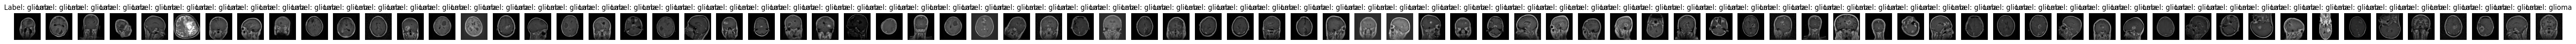

In [ ]:
import matplotlib.pyplot as plt
import numpy as np # Ensure numpy is imported for array operations
num_images_to_display =80 # Change this number as needed
plt.figure(figsize=(80, 50))
for i in range(num_images_to_display):
    plt.subplot(1, num_images_to_display, i + 1)
    image_to_display = np.asarray(all_images[i]).astype(np.float32)
    plt.imshow(image_to_display)
    plt.title(f"Label: {all_labels[i]}")
    plt.axis('off')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(all_images, all_labels, test_size=0.3, random_state=42)
print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (2912, 64, 64, 3)
Test data shape: (1248, 64, 64, 3)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),  # Adjust input shape based on
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(np.unique(all_labels)), activation='softmax')  # Number of classes
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
# Print the model summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,668 (6.20 MB)

 Trainable params: 1,625,668 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
print(f"Number of images: {len(all_images)}")
for i in range(50):  # Check first 50 images
    print(f"Shape of image {i}: {all_images[i].shape}")
try:
    all_images = np.array([image for image in all_images])  # Create a NumPy array from the list
    print(f"all_images shape after conversion: {all_images.shape}")  # Should be (N, 64, 64, 3)
except ValueError as e:
    print(f"Error converting to array: {e}")
if all_images.ndim == 3:  # This means we have (N, 64, 64)
    all_images = all_images.reshape(all_images.shape[0], 64, 64, 1)  # Add channel dimension
print(f"Reshaped all_images shape: {all_images.shape}")  # Now should be (N, 64, 64, 1) or (N, 64, 64, 3)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(all_images, all_labels, test_size=0.2, random_state=4)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Number of images: 4160
Shape of image 0: (64, 64, 3)
Shape of image 1: (64, 64, 3)
Shape of image 2: (64, 64, 3)
Shape of image 3: (64, 64, 3)
Shape of image 4: (64, 64, 3)
Shape of image 5: (64, 64, 3)
Shape of image 6: (64, 64, 3)
Shape of image 7: (64, 64, 3)
Shape of image 8: (64, 64, 3)
Shape of image 9: (64, 64, 3)
Shape of image 10: (64, 64, 3)
Shape of image 11: (64, 64, 3)
Shape of image 12: (64, 64, 3)
Shape of image 13: (64, 64, 3)
Shape of image 14: (64, 64, 3)
Shape of image 15: (64, 64, 3)
Shape of image 16: (64, 64, 3)
Shape of image 17: (64, 64, 3)
Shape of image 18: (64, 64, 3)
Shape of image 19: (64, 64, 3)
Shape of image 20: (64, 64, 3)
Shape of image 21: (64, 64, 3)
Shape of image 22: (64, 64, 3)
Shape of image 23: (64, 64, 3)
Shape of image 24: (64, 64, 3)
Shape of image 25: (64, 64, 3)
Shape of image 26: (64, 64, 3)
Shape of image 27: (64, 64, 3)
Shape of image 28: (64, 64, 3)
Shape of image 29: (64, 64, 3)
Shape of image 30: (64, 64, 3)
Shape of image 31: (64, 64

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(all_images, all_labels, test_size=0.2, random_state=4)
print(f"X_train shape: {X_train.shape}")  # Should be (num_samples, 64, 64, 3)
print(f"X_test shape: {X_test.shape}")  # Should be (num_samples, 64, 64, 3)

X_train shape: (3328, 64, 64, 3)
X_test shape: (832, 64, 64, 3)


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

print(f"Unique labels in y_train before encoding: {np.unique(y_train)}")
print(f"Unique labels in y_test before encoding: {np.unique(y_test)}")

# Only perform encoding if the labels are string/object type
if isinstance(y_train[0], (str, np.str_)):
    label_encoder = LabelEncoder()
    label_encoder.fit(all_labels)
    y_train = label_encoder.transform(y_train)
    y_test = label_encoder.transform(y_test)
    print("Labels have been successfully encoded.")
else:
    print("Labels are already numeric/encoded. No encoding needed.")

print(f"Unique labels in y_train after encoding: {np.unique(y_train)}")
print(f"Unique labels in y_test after encoding: {np.unique(y_test)}")

Unique labels in y_train before encoding: ['glioma' 'meningioma' 'no_tumor' 'pituitary']
Unique labels in y_test before encoding: ['glioma' 'meningioma' 'no_tumor' 'pituitary']
Labels have been successfully encoded.
Unique labels in y_train after encoding: [0 1 2 3]
Unique labels in y_test after encoding: [0 1 2 3]


In [ ]:
import tensorflow as tf
# Convert NumPy arrays to TensorFlow Tensors with explicit dtypes
X_train_tf = tf.convert_to_tensor(X_train, dtype=tf.float32)
y_train_tf = tf.convert_to_tensor(y_train, dtype=tf.int32)
X_test_tf = tf.convert_to_tensor(X_test, dtype=tf.float32)
y_test_tf = tf.convert_to_tensor(y_test, dtype=tf.int32)
history = model.fit(X_train_tf, y_train_tf, epochs=10, batch_size=32, validation_split=0.2)
# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(X_test_tf, y_test_tf)
print(f'Test accuracy: {test_acc:.4f}')

Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 323ms/step - accuracy: 0.6503 - loss: 0.8548 - val_accuracy: 0.7297 - val_loss: 0.7231
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 29s 351ms/step - accuracy: 0.6465 - loss: 0.8626 - val_accuracy: 0.7327 - val_loss: 0.7243
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 28s 329ms/step - accuracy: 0.6698 - loss: 0.8315 - val_accuracy: 0.7252 - val_loss: 0.7230
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 40s 320ms/step - accuracy: 0.6653 - loss: 0.8428 - val_accuracy: 0.7402 - val_loss: 0.7181
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 41s 319ms/step - accuracy: 0.6792 - loss: 0.8085 - val_accuracy: 0.7447 - val_loss: 0.7121
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 322ms/step - accuracy: 0.6698 - loss: 0.8349 - val_accuracy: 0.7387 - val_loss: 0.7144
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.6582 - loss: 0.8360 - val_accuracy: 0.7417 - val_loss: 0.7126
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 28s 331ms/step - accuracy: 0.6709 - loss: 0.8293 - val_accu

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2

# 1. Real-time Data Augmentation Layers to improve generalization
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])

# 2. Load pre-trained MobileNetV2 base
base_model = MobileNetV2(input_shape=(64, 64, 3), include_top=False, weights='imagenet')

# Initially freeze the base model
base_model.trainable = False

# 3. Build Transfer Learning Model with Augmentation
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(4, activation='softmax')
])

# 4. Phase 1: Train the classification head only (warm-up)
model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

X_train_tf = tf.convert_to_tensor(X_train, dtype=tf.float32)
y_train_tf = tf.convert_to_tensor(y_train, dtype=tf.int32)
X_test_tf = tf.convert_to_tensor(X_test, dtype=tf.float32)
y_test_tf = tf.convert_to_tensor(y_test, dtype=tf.int32)

print("--- Phase 1: Training Classification Head ---")
model.fit(
    X_train_tf,
    y_train_tf,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# 5. Phase 2: Fine-Tuning
# Unfreeze the base model
base_model.trainable = True

# Let's see how many layers are in the base model
print(f"Number of layers in the base model: {len(base_model.layers)}")

# Freeze all layers up to layer 100
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with a very low learning rate
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n--- Phase 2: Fine-tuning Base Model Layers ---")
history = model.fit(
    X_train_tf,
    y_train_tf,
    epochs=15,
    batch_size=32,
    validation_split=0.2
)

# Evaluate the final model on the test set
test_loss, test_acc = model.evaluate(X_test_tf, y_test_tf)
print(f'\nFine-Tuned Model - Test accuracy: {test_acc:.4f}')

/tmp/ipykernel_484/178355212.py:13: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(64, 64, 3), include_top=False, weights='imagenet')


--- Phase 1: Training Classification Head ---
Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 24s 196ms/step - accuracy: 0.5496 - loss: 1.2787 - val_accuracy: 0.6351 - val_loss: 1.0389
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 169ms/step - accuracy: 0.6168 - loss: 0.9611 - val_accuracy: 0.6441 - val_loss: 0.8839
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 168ms/step - accuracy: 0.6518 - loss: 0.8765 - val_accuracy: 0.6517 - val_loss: 0.8652
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 168ms/step - accuracy: 0.6698 - loss: 0.8243 - val_accuracy: 0.6967 - val_loss: 0.7505
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 21s 175ms/step - accuracy: 0.6589 - loss: 0.8178 - val_accuracy: 0.6592 - val_loss: 0.8363
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 21s 176ms/step - accuracy: 0.6841 - loss: 0.7800 - val_accuracy: 0.6787 - val_loss: 0.8137
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.6912 - loss: 0.7764 - val_accuracy: 0.6952 - val_loss: 0.7498
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/ste

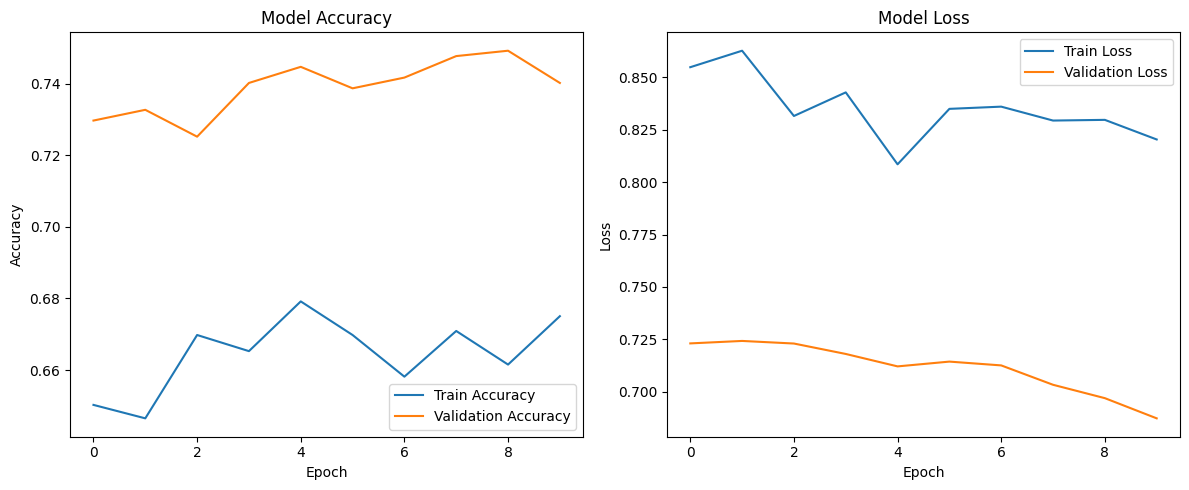

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


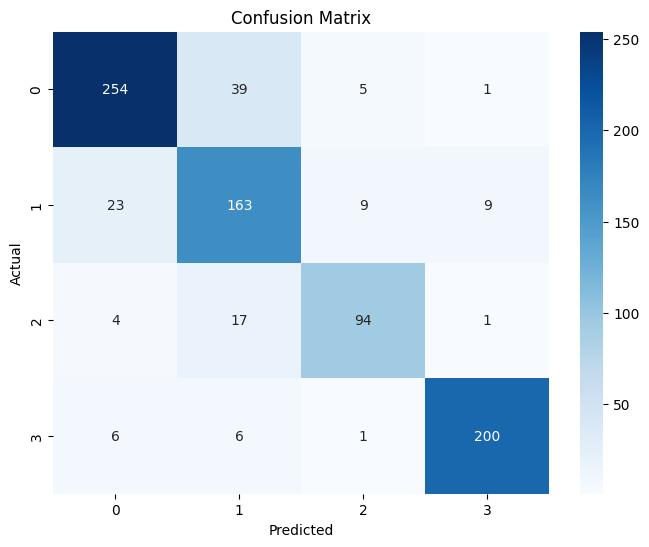

              precision    recall  f1-score   support

           0       0.89      0.85      0.87       299
           1       0.72      0.80      0.76       204
           2       0.86      0.81      0.84       116
           3       0.95      0.94      0.94       213

    accuracy                           0.85       832
   macro avg       0.85      0.85      0.85       832
weighted avg       0.86      0.85      0.86       832



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
# Make predictions on the test set
y_pred = model.predict(X_test_tf)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert probabilities to class labels
# Generate the confusion matrix
cm = confusion_matrix(y_test_tf, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3]) #
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()
# Print classification report
print(classification_report(y_test_tf, y_pred_classes))

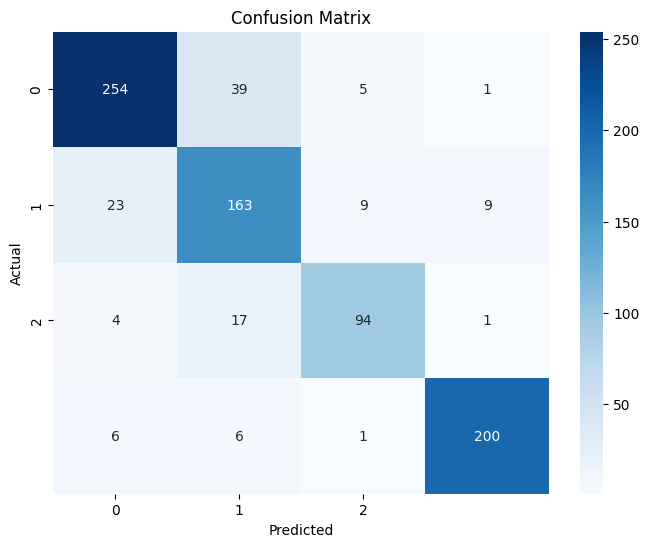

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
# Visualize the confusion matrix again for a clearer understanding
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0, 1, 2], yticklabels=[0, 1, 2])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Save the model in HDF5 format
model.save('my_model.keras')
# Load the model
from tensorflow.keras.models import load_model
loaded_model = load_model('my_model.keras')